## Demo script for working with cloudy_outputs.py
### Example data from [Cooper+26](https://arxiv.org/abs/2609.01205)
cloudy_outputs automatically processes the outputs from cloudy. Currently this supports the grid file, continuum file and line fluxes file.

In [1]:
# Import cloudy_outputs
import cloudy_outputs

# Import other modules
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
from itertools import product

# Plotting parameters
plt.rcParams['xtick.major.size'] = 6
plt.rcParams['xtick.major.width'] = 1
plt.rcParams['xtick.minor.size'] = 3
plt.rcParams['xtick.minor.visible'] = True
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.major.size'] = 6
plt.rcParams['ytick.minor.size'] = 3
plt.rcParams['ytick.minor.visible'] = True
plt.rcParams['ytick.major.width'] = 1
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['xtick.labelsize']=16
plt.rcParams['ytick.labelsize']=16

plt.rcParams.update({
    "text.usetex": True,
    "font.family": 'Andale',
    'figure.dpi': 300
})



### Process individual files
cloudy_outputs can process, grid, line flux, and continuum files individually.

In [2]:
lines = cloudy_outputs.read_cloudy_lines('./Cooper_26/sp_model_27.lin')
grid = cloudy_outputs.read_cloudy_grid('./Cooper_26/sp_model_27.grd')
cont = cloudy_outputs.read_cloudy_spectrum('./Cooper_26/sp_model_27.con')

In [3]:
grid[:3]

index,failure,warnings,exit_code,rank,seq,TABLE STA,HDEN,METALS
int64,bool,bool,str2,int64,int64,float64,float64,float64
0,False,False,ok,0,5,6.0,1.0,0.0
1,False,False,ok,3,10,6.0,1.0,-0.5
2,False,False,ok,3,6,6.0,1.0,-1.0


## Process all outputs
get_cloudy_table will collect the grid, line fluxes and spectrum from each model and append it to a single table.

In [4]:
dat = cloudy_outputs.get_cloudy_table('./Cooper_26/sp_model_27')
dat[:3]

index,failure,warnings,exit_code,rank,seq,TABLE STA,HDEN,METALS,Blnd_3727A,Ne3_3869A,Ne3_3967A,H1_4340A,O3_4363A,He2_4686A,H1_4861A,O3_5007A,O1_6300A,N2_6548A,H1_6563A,N2_6583A,Blnd_6720A,S3_9069A,S3_9531A,C1_9850A,H1_1.005m,H1_1.094m,H1_1.282m,H1_1.875m,wave,flux_incident,flux_nebular,flux_total
int64,bool,bool,str2,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,object,object,object,object
0,False,False,ok,0,5,6.0,1.0,0.0,0.0025015,0.00019427,5.8963e-05,0.00069156,7.1186e-06,6.3296e-07,0.001474,0.0035012,8.2292e-05,0.00031124,0.0041394,0.00091749,0.00099096,0.00042286,0.0010622,3.3032e-06,8.2443e-05,0.0001335,0.00023831,0.00047516,[1.29661989e-04 1.33601002e-04 1.37659663e-04 ... 2.97304183e+11\n 2.98296851e+11 2.99293222e+11],[0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 3.62927958e-26\n 3.58032609e-26 3.53165366e-26],[0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 7.12065327e-22\n 7.03996704e-22 6.95972996e-22],[0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 7.12065327e-22\n 7.03996704e-22 6.95972996e-22]
1,False,False,ok,3,10,6.0,1.0,-0.5,0.0035613,0.00034677,0.00010525,0.00068682,4.6126e-05,7.2105e-07,0.001454,0.0052235,7.4358e-05,0.00024059,0.0040354,0.00070921,0.00070836,0.00032935,0.00082731,2.6793e-06,7.789e-05,0.00012549,0.00022249,0.00043583,[1.29661989e-04 1.33601002e-04 1.37659663e-04 ... 2.96315209e+11\n 2.97304183e+11 2.98296851e+11],[0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 3.67514042e-26\n 3.62927958e-26 3.58032609e-26],[0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 1.10389204e-21\n 1.09181108e-21 1.08013209e-21],[0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 1.10389204e-21\n 1.09181108e-21 1.08013209e-21]
2,False,False,ok,3,6,6.0,1.0,-1.0,0.0020304,0.00022942,6.9633e-05,0.00069423,5.5725e-05,7.9032e-07,0.0014666,0.0032436,3.2096e-05,0.00010648,0.0040939,0.00031388,0.00030437,0.0001548,0.00038885,1.2708e-06,7.569e-05,0.00012168,0.00021689,0.0004216,[1.29661989e-04 1.33601002e-04 1.37659663e-04 ... 2.96315209e+11\n 2.97304183e+11 2.98296851e+11],[0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 3.67514042e-26\n 3.62927958e-26 3.58032609e-26],[0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 1.35430106e-21\n 1.34004169e-21 1.32619570e-21],[0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 1.35430106e-21\n 1.34004169e-21 1.32619570e-21]


## Working with outputted emission lines
### Plotting line ratio estimates and comparing to a strong line calibration
We can load parameters from the data table and plot line ratio variations with specific paramters. 

Here we plot the variation of [OIII]/Hb with gas-phase metallicity for various stellar ages and densities.

Text(0, 0.5, 'log([OIII]/H$\\beta$)')

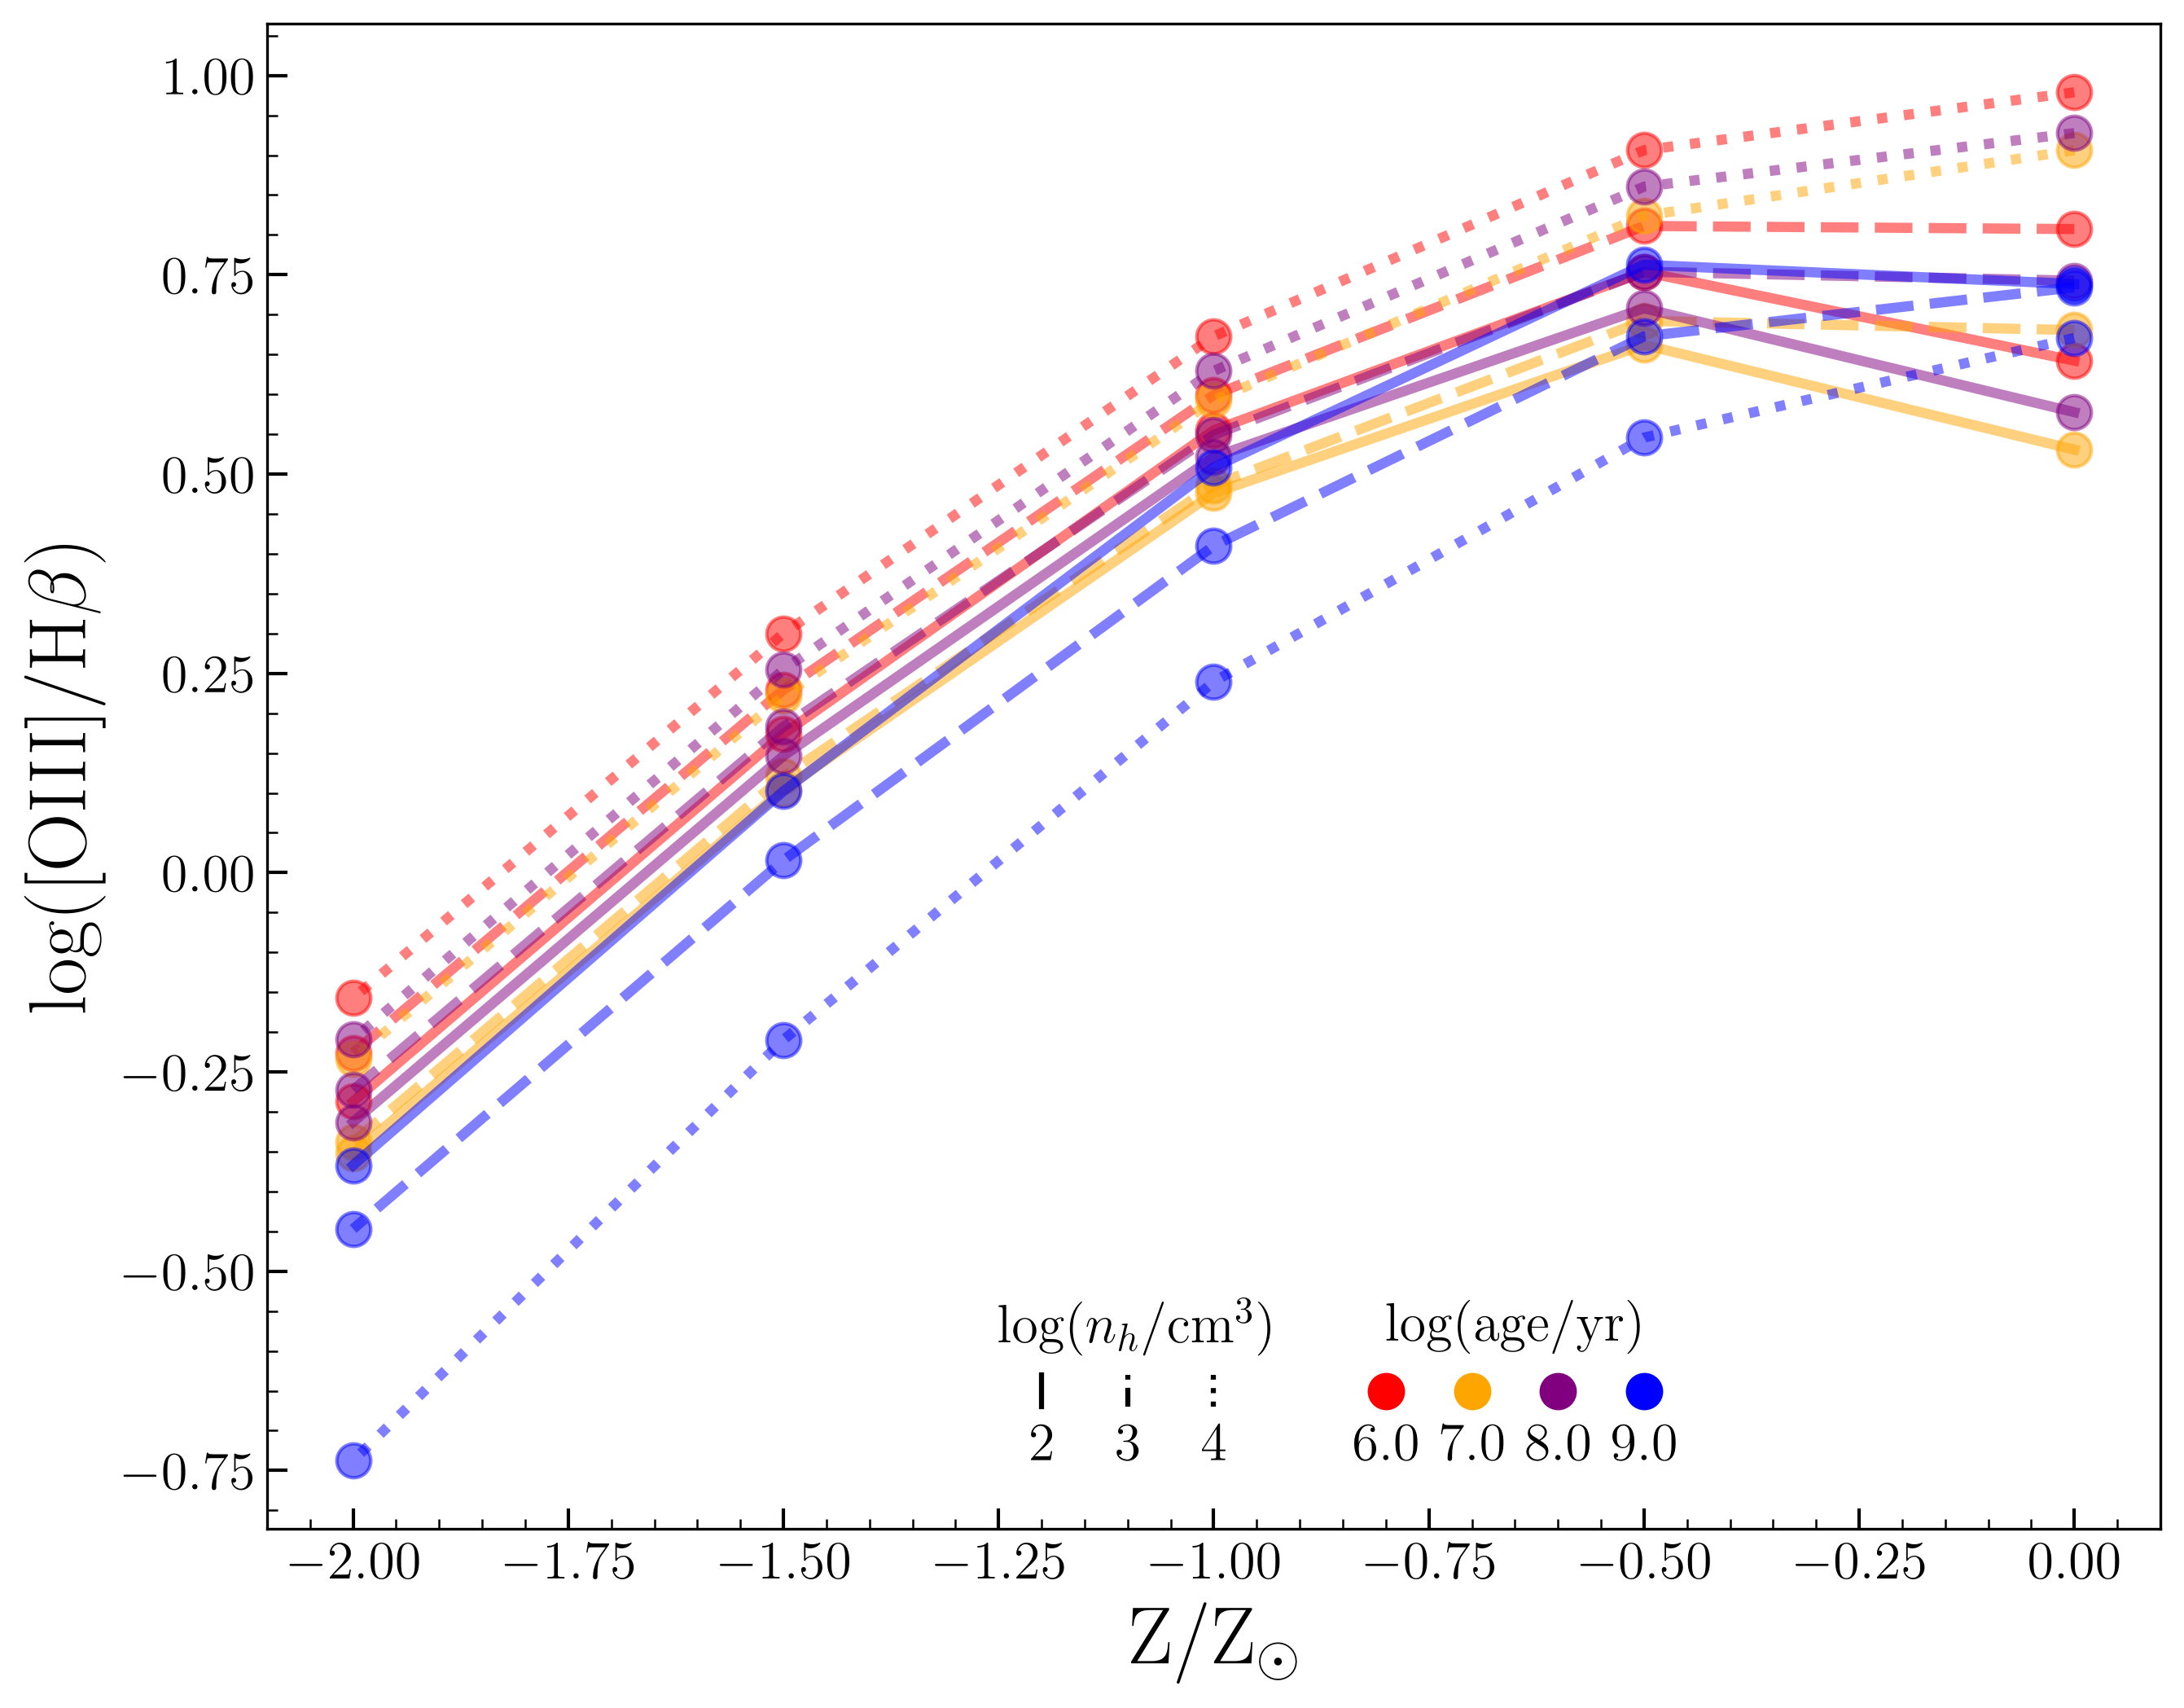

In [5]:
# Load [OIII] and Hb from data
o3 = dat['O3_5007A']
hb = dat['H1_4861A']    # Balmer lines are recorded as H1 in cloudy

# Define the grids over which to plot
STELLAR_AGE = [6.0, 7.0, 8.0, 9.0]
DENSITY = [2,3,4]

# Define the gas-phase metallicity points (should be equivalent to that in the data file)
GAS_MET = [0, -0.5, -1.0, -1.5, -2.0]

colours = ['red','orange','purple','blue']
linestyles = ['-','--',':']

color_of = {a: colours[i % len(colours)] for i, a in enumerate(STELLAR_AGE)}
style_of = {d: linestyles[i % len(linestyles)] for i, d in enumerate(DENSITY)}

fig, ax = plt.subplots(1,1,figsize=(10,8))

for age, dens in product(STELLAR_AGE, DENSITY):
    td = (dat['TABLE STA']==age) & (dat['HDEN']==dens)
    ax.plot(GAS_MET, np.log10(o3[td]/hb[td]), marker='o', markersize=10, c=color_of[age], linestyle=style_of[dens], alpha=0.5, lw=3)

# Plot the legend
x_base = -0.8
y_base = -0.65
x_pad = 0.1

# Plot stellar ages
for i in range(len(STELLAR_AGE)):
    ax.scatter(x_base+(i*x_pad), y_base, c=colours[i], s=100)
    ax.text(x_base+(i*x_pad), y_base-0.07, STELLAR_AGE[i], fontsize=16, ha='center', va='center')

ax.text(x_base+0.15,y_base+0.08,r'log(age/yr)',fontsize=16, ha='center', va='center')


# Plot densities
x_base_den = -1.2
for i in range(len(DENSITY)):
    ax.plot([x_base_den+(i*x_pad),x_base_den+(i*x_pad)],[y_base-0.02,y_base+0.02],linestyle=linestyles[i], c='black')
    ax.text(x_base_den+(i*x_pad), y_base-0.07, DENSITY[i], fontsize=16, ha='center', va='center')
ax.text(x_base_den+0.11,y_base+0.08,r'log($n_h$/cm$^3$)',fontsize=16, ha='center', va='center')

ax.set_xlabel(r'Z/Z$_\odot$', fontsize=24)
ax.set_ylabel(r'log([OIII]/H$\beta$)', fontsize=24)




## Working with outputted spectra
### Examine the relative contributions from the nebular and stellar components to the final outputted spectrum

Text(1600, 0.0017000000000000001, 'log($n_h/cm^3$)=2.0')

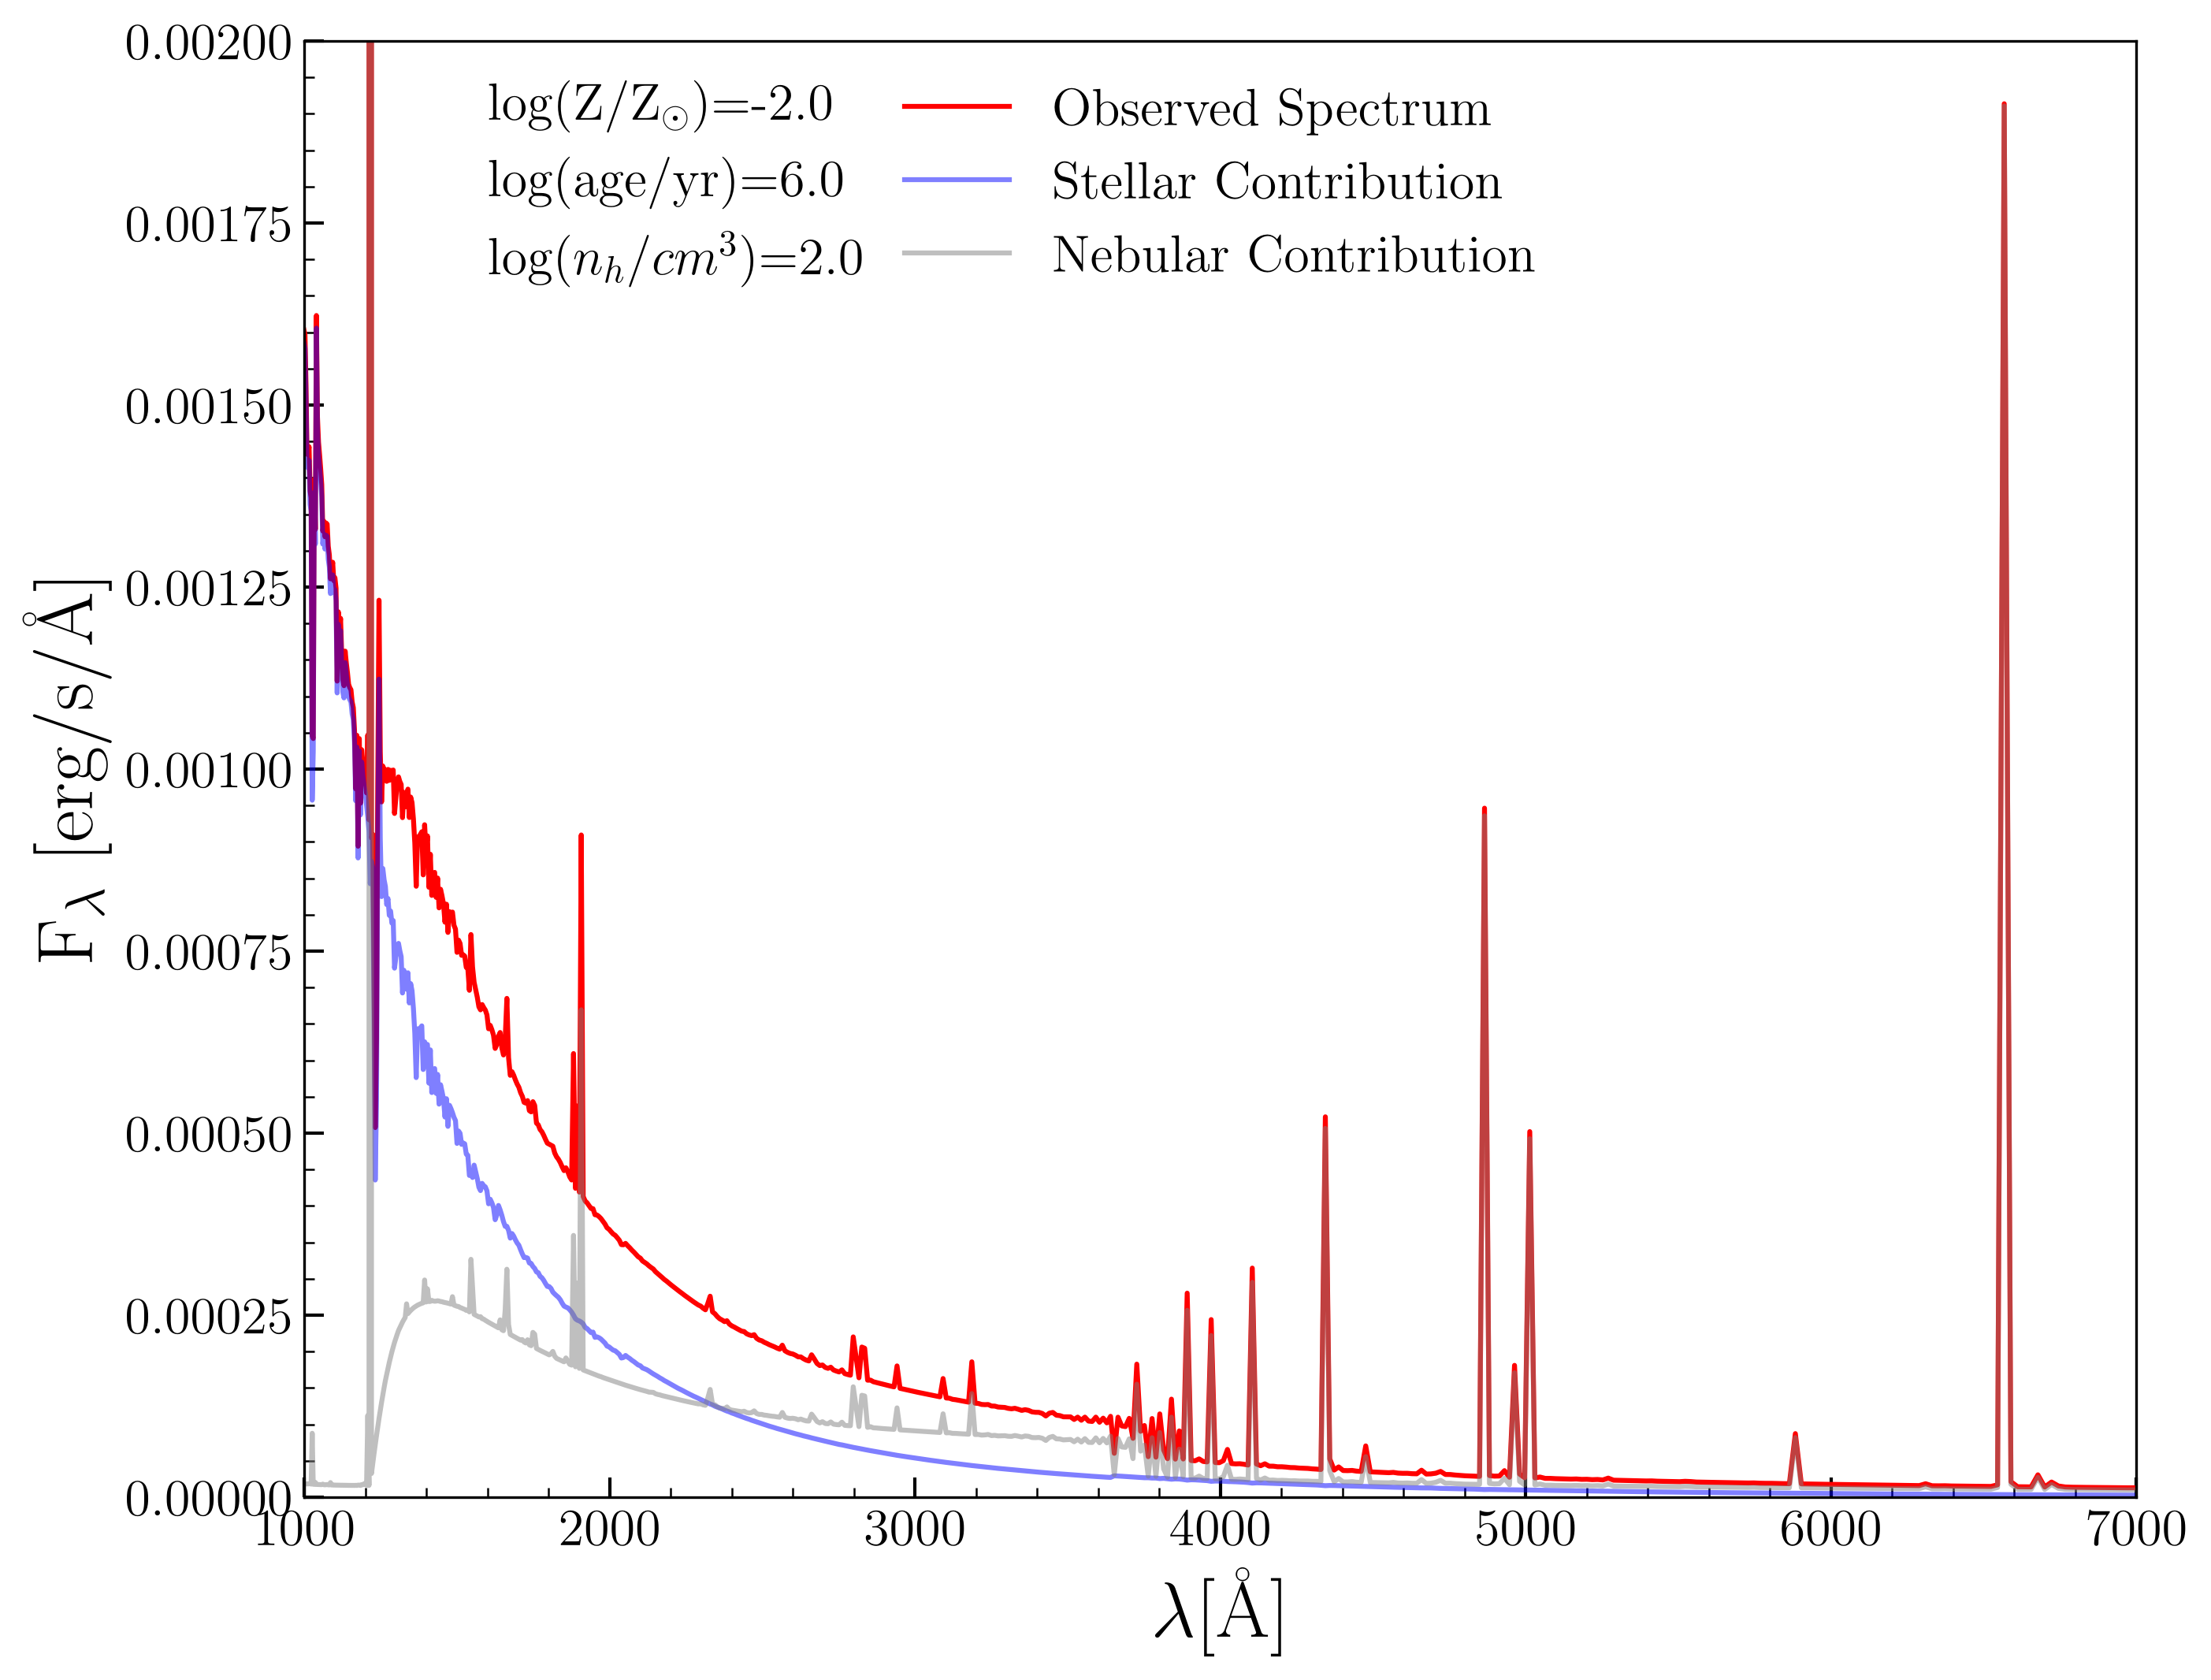

In [6]:
# Get an outputted spectrum from a random model
model_ind = 9

# Get the parameters for this model, the values we care about are gas-phase metallicity, stellar age, and gas density
hden = dat['HDEN'][9]
z_gas = dat['METALS'][9]
age_star = dat['TABLE STA'][9]

wl = dat['wave'][model_ind]
total_flux = dat['flux_total'][model_ind]
stellar_flux = dat['flux_incident'][model_ind]
nebular_flux = dat['flux_nebular'][model_ind]

# Plot the various spectrum components
fig,ax = plt.subplots(1,1,figsize=(10,8))
ax.plot(wl, total_flux, color='red', label='Observed Spectrum')
ax.plot(wl, stellar_flux, alpha=0.5, color='blue', label='Stellar Contribution')
ax.plot(wl, nebular_flux, alpha=0.5, color='grey', label='Nebular Contribution')
ax.set_xlim(1000,7000)
ax.set_ylim(0, 0.002)
ax.legend(frameon=False, fontsize=16)
ax.set_xlabel(r'$\lambda [\rm{\AA}]$', fontsize=24)
ax.set_ylabel(r'F$_\lambda$ [erg/s/\rm{\AA}]', fontsize=24)

# Add the model information
x_base = 1600
y_base = 0.00191
ax.text(x_base, y_base, r'log(Z/Z$_\odot$)=%.1f'%(z_gas), fontsize=16, ha='left', va='center')
ax.text(x_base, y_base-0.000105, r'log(age/yr)=%.1f'%(age_star), fontsize=16, ha='left', va='center')
ax.text(x_base, y_base-0.000210, r'log($n_h/cm^3$)=%.1f'%(hden), fontsize=16, ha='left', va='center')


## Run the spectrum through an IGM attenuation curve
### Using the attenuation model described in [Asada+24](https://arxiv.org/abs/2410.21543)

/opt/anaconda3/envs/Py311/lib/python3.11/site-packages/eazy/igm.py:321: RuntimeWarning: overflow encountered in exp
  igmz = np.exp(-self.scale_tau * (tau_LC + tau_LS + tau_clip))
/var/folders/l3/wzx_d9lj4dv62wqm7fcrjgfc0000gn/T/ipykernel_46931/1272141977.py:8: RuntimeWarning: invalid value encountered in multiply
  ax.plot(wl, total_flux*T, color='red')


Text(0, 0.5, 'F$_\\lambda$ [erg/s/\\rm{\\AA}]')

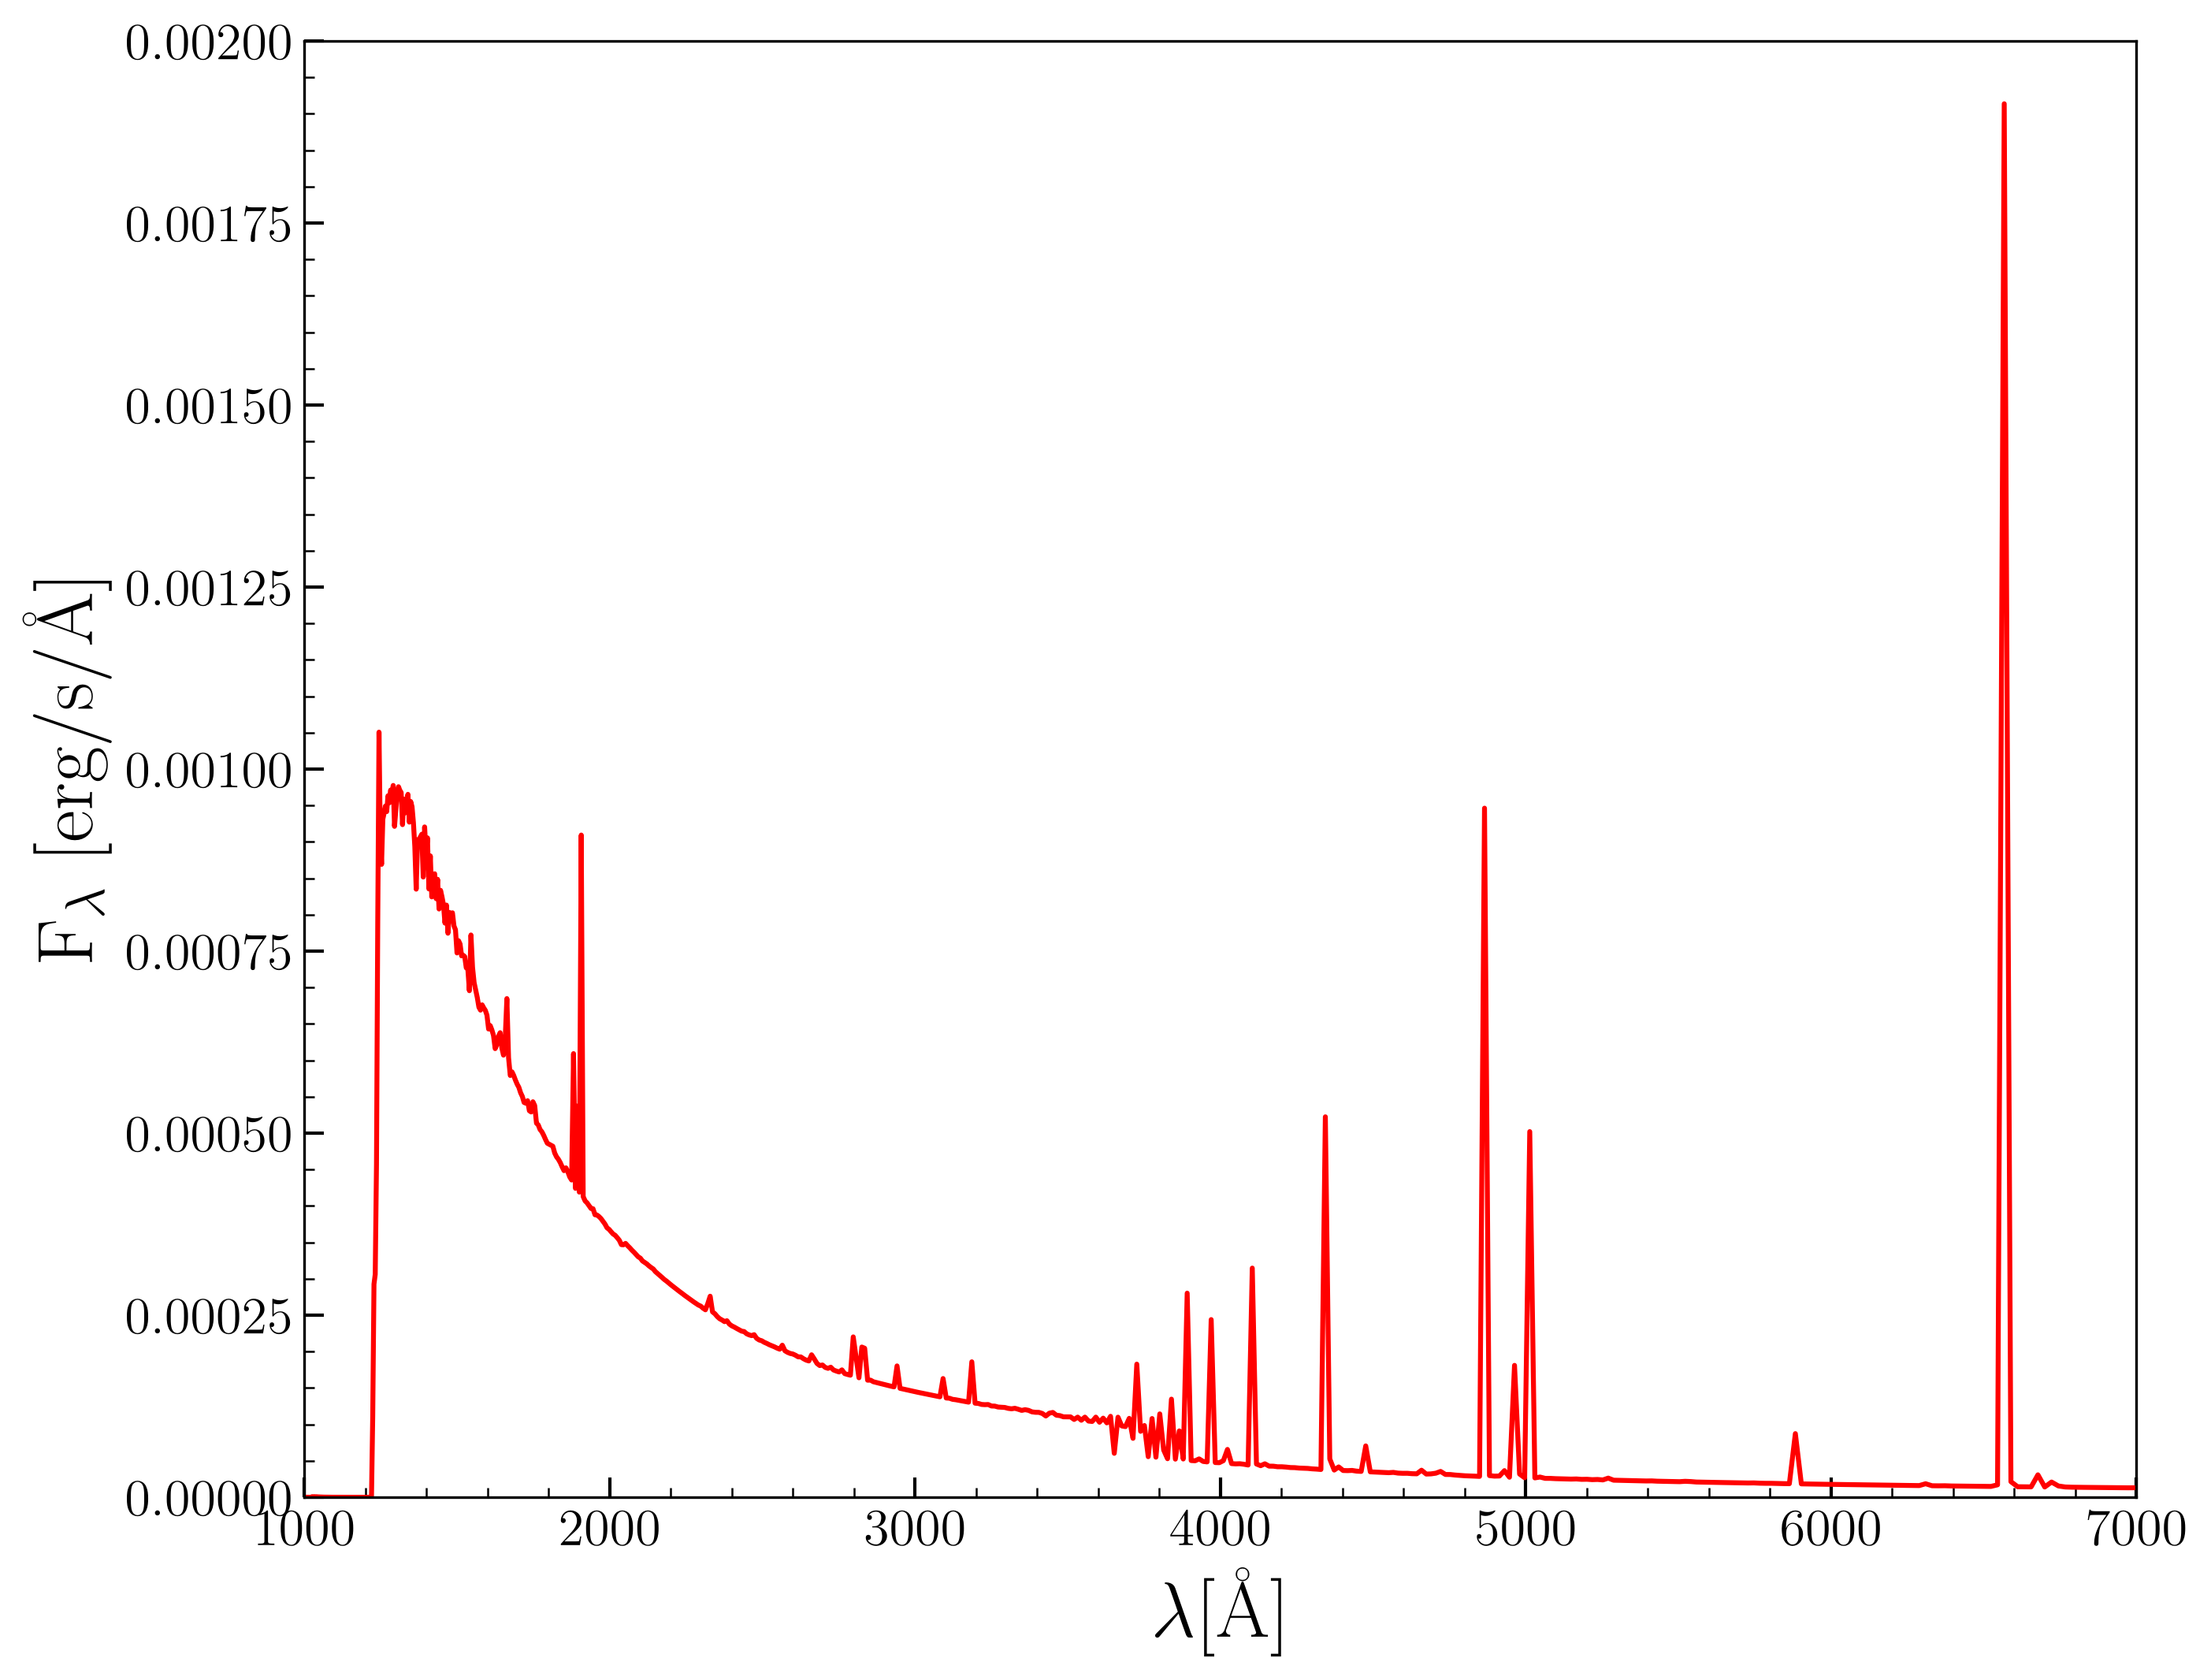

In [7]:
import eazy.igm

# IGM model from Asada+24
z = 8.0
T = eazy.igm.Asada24().full_IGM(z, wl*(1+z))

fig,ax = plt.subplots(1,1,figsize=(10,8))
ax.plot(wl, total_flux*T, color='red')
ax.set_xlim(1000,7000)
ax.set_ylim(0, 0.002)
ax.set_xlabel(r'$\lambda [\rm{\AA}]$', fontsize=24)
ax.set_ylabel(r'F$_\lambda$ [erg/s/\rm{\AA}]', fontsize=24)

## Introduce dust attenuation
### Using the dust attenuation model described in [Calzetti+2000](https://arxiv.org/abs/astro-ph/9911459)

/var/folders/l3/wzx_d9lj4dv62wqm7fcrjgfc0000gn/T/ipykernel_46931/1032238996.py:11: RuntimeWarning: invalid value encountered in multiply
  ax.plot(wl, apply(calzetti00(wl, ebv[e], 3.1),total_flux*T),c=cs[e])


Text(1160, 0.00191, 'E(B-V)')

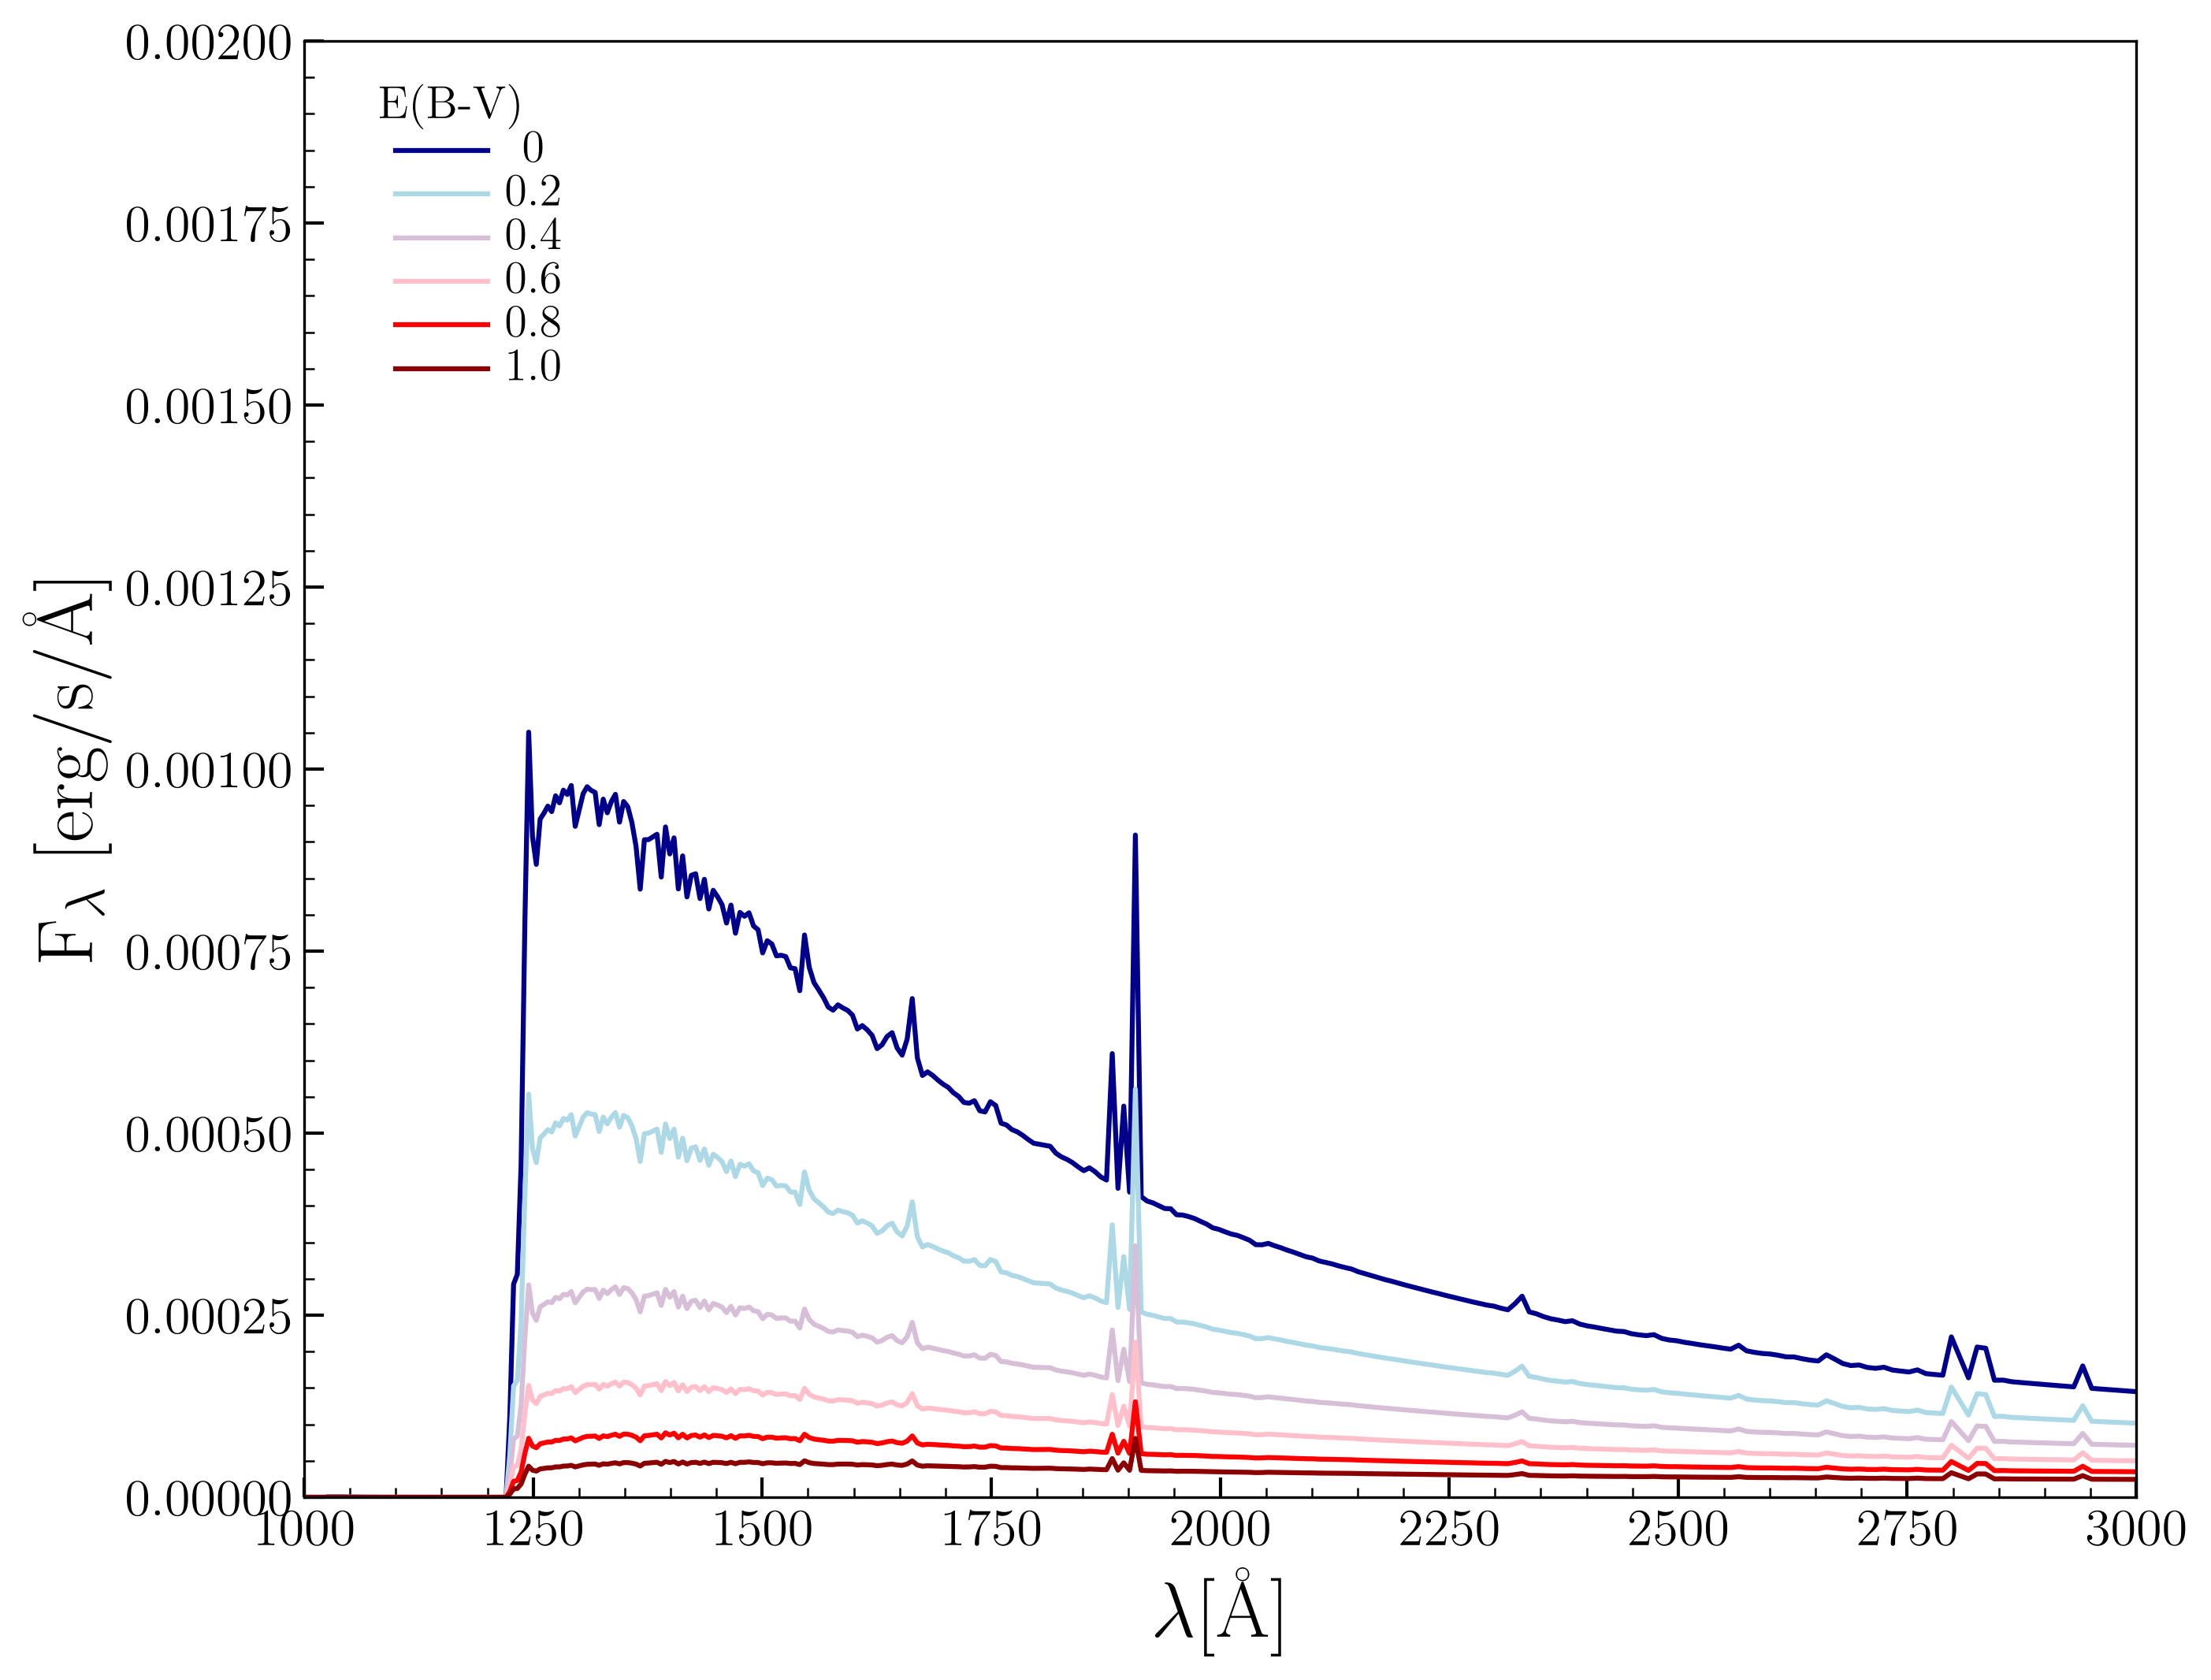

In [10]:
from extinction import calzetti00
from extinction import apply

fig,ax = plt.subplots(1,1,figsize=(10,8))

cs = ['darkblue','lightblue','thistle','pink','red','darkred']

# Attenuate the spectrum using the Calzetti dust extinction law
ebv = (0, 0.2, 0.4, 0.6, 0.8, 1.0)
for e in range(len(ebv)):
    ax.plot(wl, apply(calzetti00(wl, ebv[e], 3.1),total_flux*T),c=cs[e])


# Isolate the rest-UV spectrum
ax.set_xlim(1000,3000)
ax.set_ylim(0, 0.002)
ax.set_xlabel(r'$\lambda [\rm{\AA}]$', fontsize=24)
ax.set_ylabel(r'F$_\lambda$ [erg/s/\rm{\AA}]', fontsize=24)

# Plot the legend
x_base = 1100
y_base = 0.00185
y_pad = 0.00006
for e in range(len(ebv)):
    ax.plot([x_base,x_base+100],[y_base-(e*y_pad),y_base-(e*y_pad)], c=cs[e])
    ax.text(x_base+150, y_base-(e*y_pad), ebv[e], ha='center', va='center', fontsize=14)

ax.text(x_base+60, y_base+y_pad, 'E(B-V)', fontsize=14, ha='center', va='center')
